# Decision Trees and Random Forests

> Learn nonlinear decision rules, ensemble averaging, and feature-importance caveats.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Train a shallow decision tree and a random forest.
- Visualize a small tree and compare overfitting behavior.
- Understand bootstrap aggregation and feature importance limitations.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score

X, y = load_breast_cancer(return_X_y=True, as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=17)
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=8, random_state=17).fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=250, min_samples_leaf=3, class_weight="balanced", random_state=17, n_jobs=1).fit(X_train, y_train)
for name, estimator in [("Tree", tree), ("Random forest", forest)]:
    p = estimator.predict_proba(X_test)[:, 1]
    print(name, "accuracy:", round(accuracy_score(y_test, estimator.predict(X_test)),3), "ROC-AUC:", round(roc_auc_score(y_test,p),3))

Tree accuracy: 0.965 ROC-AUC: 0.977
Random forest accuracy: 0.982 ROC-AUC: 0.999


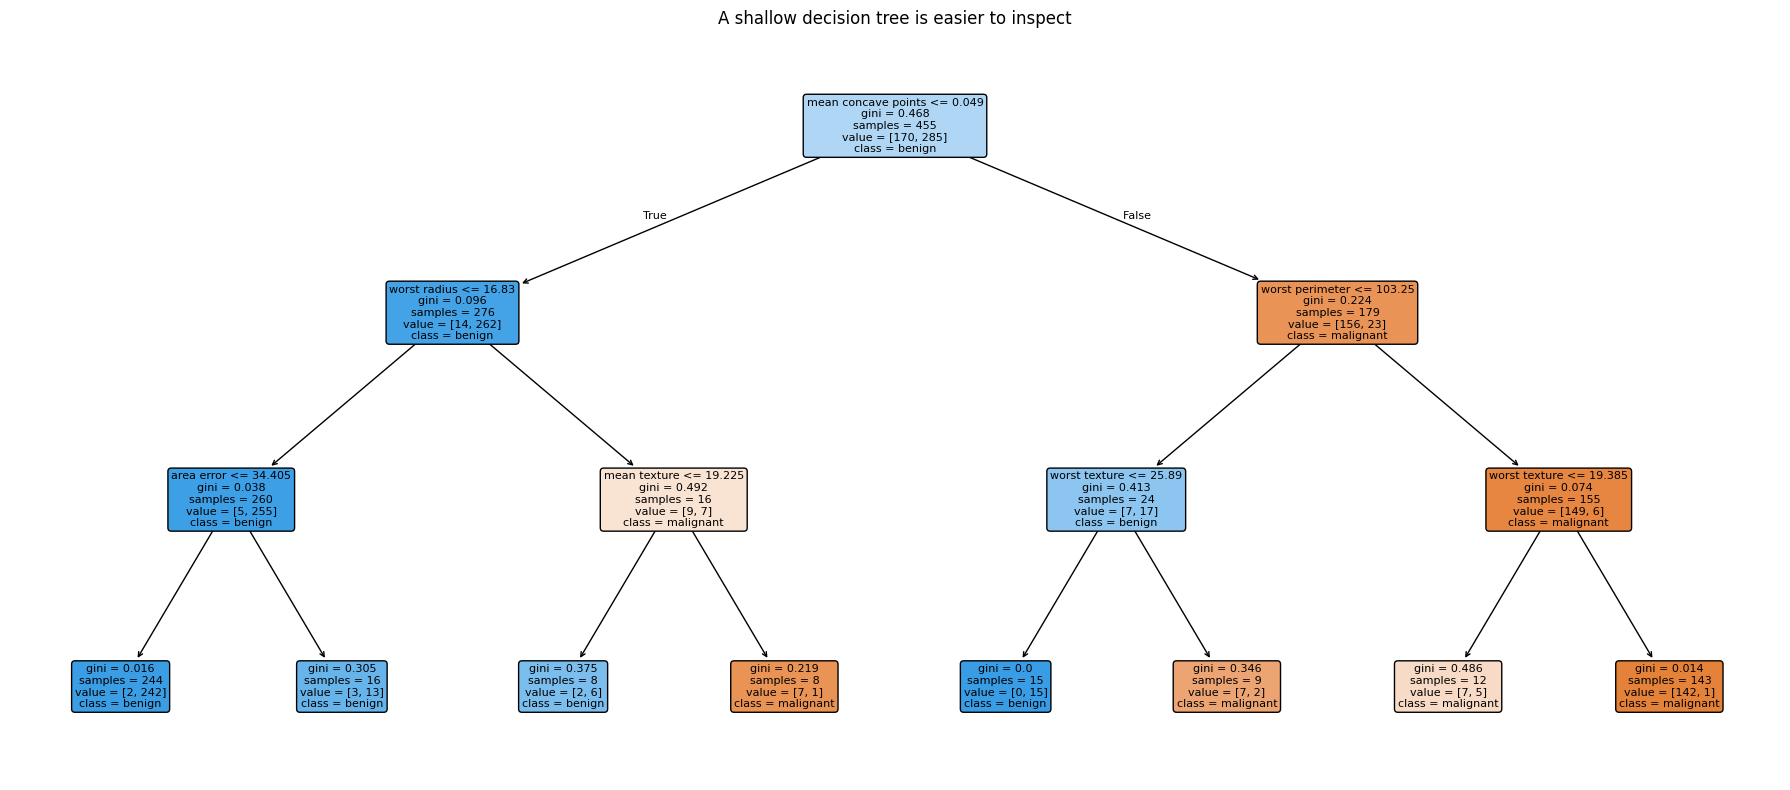

In [2]:
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=list(X.columns), class_names=list(load_breast_cancer().target_names), filled=True, rounded=True, max_depth=3, fontsize=8)
plt.title("A shallow decision tree is easier to inspect")
plt.tight_layout()

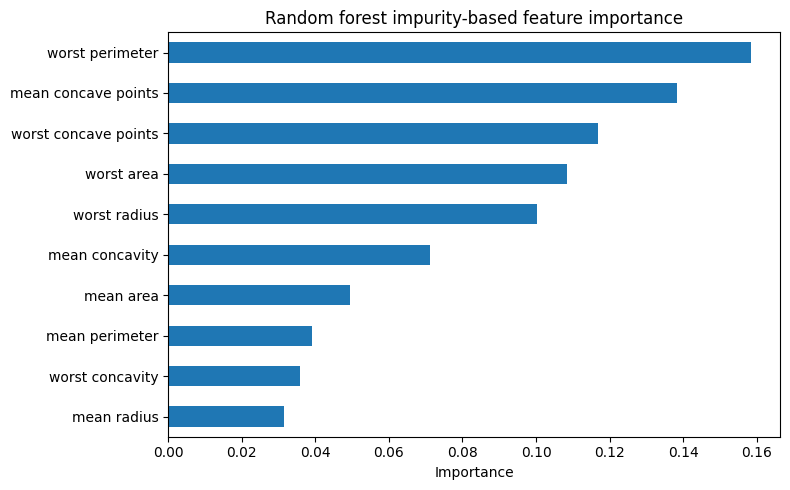

In [3]:
importance = pd.Series(forest.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importance.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Random forest impurity-based feature importance")
plt.xlabel("Importance")
plt.tight_layout()

## Limitations and practical notes
- Trees do not need feature scaling, but can form unstable decision boundaries when the data change slightly.
- Deep trees may overfit; `max_depth`, `min_samples_leaf`, and pruning can control complexity.
- Impurity-based importance can favor high-cardinality features and does not measure causal impact. Compare with permutation importance on held-out data.
- Forest probabilities may still need calibration for threshold-sensitive use cases.

## Practice
Change the tree depth to 1, 3, and 10. Compare train and test scores. What pattern suggests overfitting?

In [4]:
for depth in [1, 3, 10, None]:
    est = DecisionTreeClassifier(max_depth=depth, random_state=17).fit(X_train, y_train)
    print("depth=", depth, "train=", round(est.score(X_train,y_train),3), "test=", round(est.score(X_test,y_test),3))

depth= 1 train= 0.919 test= 0.895
depth= 3 train= 0.974 test= 0.982
depth= 10 train= 1.0 test= 0.965
depth= None train= 1.0 test= 0.965
